# Maximum mixed layer depth in ACCESS-OM3

Related issue: https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/38

Requires access to `/g/data/av17`

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-5/"
nbname = "MLD_max.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from model_agnostic import patch_broken_conda_env
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs

In [4]:
import xarray as xr
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import intake
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from distributed import Client
import cftime
import os
import matplotlib.pyplot as plt
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft
from textwrap import wrap
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default

In [5]:
client = Client(threads_per_worker=1)
from model_agnostic import patch_dask_workers
patch_dask_workers(client)  # patch workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:38205,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:43823,Total threads: 1
Dashboard: http://127.0.0.1:45671/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:44767,


### Define plot function

In [6]:
blue_marble = plt.imread('/g/data/ik11/grids/BlueMarble.tiff')
blue_marble_extent = (-180, 180, -90, 90)

In [7]:
#cb - Jan 25 - tweaked to make it easier to interpret what's going on (to me at least!)
def plot(dat, **kwargs):
    levels=kwargs['levels']
    vmin=kwargs['vmin']
    vmax=kwargs['vmax']
    cmap=kwargs['cmap']
    pnum = kwargs.pop('pnum', '1')
    title = kwargs.pop('title', dat.attrs.get('long_name', ''))
    #not used in this notebook!
    #if title is None:
    #    title = dat.attrs['long_name']
    fig = plt.figure(figsize=(12, 6))
    ax = plt.axes(projection=ccrs.Robinson(central_longitude=-100))
    dat.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cbar_kwargs={"label": "\n".join(wrap(f"{dat.attrs['long_name']} [{dat.attrs['units']}]", 45)),
                     "fraction": 0.03, "aspect": 15, "shrink": 0.7},
        **kwargs
    )
    
    # Add blue marble land:
    ax.imshow(
        blue_marble, extent=blue_marble_extent, transform=ccrs.PlateCarree(), origin="upper"
    )
    
    plt.title(title)
    mkmd.savefig(fig, "Mixed Layer Depth Max", "ACCESS-OM3 maximum mixed layer depth. [GitHub issue: Time-max mixed layer depth maps](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/38)")


In [8]:
#dat=2
#plot(dat,
#        levels=51,
#        vmin=0,
#        vmax=None,
        # extend="max",
#        cmap='viridis',
#        pnum='0',
#       title="meh"
#        )

### Load and plot data from ACCESS-OM3

In [9]:
from exptdata_access import get_exptname_from_path
exptname = get_exptname_from_path(esm_file)

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
    ]
)

In [10]:
exptname

'MC_8km_jra_ryf-test2-expt-c349f800'

In [11]:
from model_agnostic import get_lon_lat_from_catalog
geolon, geolat = get_lon_lat_from_catalog(datastore)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x151d5f36dc10>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x151d5f362d20>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x151d5f367230>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x151d5f38b380>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x151d5f34a510>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x151d5f34b8f0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x151d5d77df10>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


In [12]:
variable = "mlotst_max"
model_all = datastore.search(variable=variable, frequency="1mon").to_dask(
    xarray_open_kwargs = dict(
        chunks={"time": -1},
        decode_timedelta=True
    ),
    xarray_combine_by_coords_kwargs=dict(
        compat="override",
        data_vars="minimal",
        coords="minimal"
    )
)[variable].cf.assign_coords({ "longitude": geolon, "latitude": geolat })

In [13]:
#migrating from 25km-iaf-test-for-AK-expt-7df5ef4c to MC_25km_jra_iaf-1.0-beta-5165c0f8

##### ONLY NEEDED FOR 25km-iaf-test-for-AK-expt-7df5ef4c !!!!!!!!!!!!!!!!!!!!!!!!!!!!!

# omit latitudes with grid bug https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
#model_all = model_all.isel(yh=slice(10, None))
#geolon = geolon.isel(yh=slice(10, None))
#geolat = geolat.isel(yh=slice(10, None))

In [14]:
# for IAF
model_all = model_all.convert_calendar("proleptic_gregorian", use_cftime=True)

In [15]:
model_all.time.values[0] # initial date in data

cftime.DatetimeProlepticGregorian(1900, 1, 16, 12, 0, 0, 0, has_year_zero=True)

In [16]:
model_all.time.values[-1] # final date in data

cftime.DatetimeProlepticGregorian(1909, 12, 16, 12, 0, 0, 0, has_year_zero=True)

In [17]:
# set time range

# timerange = slice(cftime.DatetimeNoLeap(1942, 1, 1, 0, 0, 0, 0),
#                   cftime.DatetimeNoLeap(1952, 1, 1, 0, 0, 0, 0))
# timerange = slice(None, None)
# datestop = model_all.time.values[-1] # final date in data
# datelist = list(cftime.to_tuple(datestop))
# datelist[0] -= 10  # last 10 years
# datestart = cftime.datetime(*datelist, calendar=datestop.calendar)
# timerange = slice(datestart, datestop)
timeranges = [ # see https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/34#issuecomment-3300900496
    slice(cftime.DatetimeProlepticGregorian(1958, 1, 1, 0, 0, 0, 0),
          cftime.DatetimeProlepticGregorian(1986, 1, 1, 0, 0, 0, 0)),
    slice(cftime.DatetimeProlepticGregorian(1986, 1, 1, 0, 0, 0, 0),
          cftime.DatetimeProlepticGregorian(2004, 1, 1, 0, 0, 0, 0)),
    slice(cftime.DatetimeProlepticGregorian(2004, 1, 1, 0, 0, 0, 0),
          cftime.DatetimeProlepticGregorian(2021, 1, 1, 0, 0, 0, 0)),
]

IAF = esm_file.find('iaf') > 0
if not IAF:
    # RYF: the periods above are IAF forcing years, so use the last (up to) 10 complete years of the run
    from model_agnostic import years_window, year_slice
    timeranges = [year_slice(years_window(model_all.time, 10))]
timeranges

[slice('1900-01-01', '1909-12-31', None)]

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-5/mkmd/MLD_max_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-5/mkmd/MLD_max.md


Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-5/mkmd/MLD_max.md successfully.
CPU times: user 2min 22s, sys: 45.4 s, total: 3min 7s
Wall time: 2min 29s


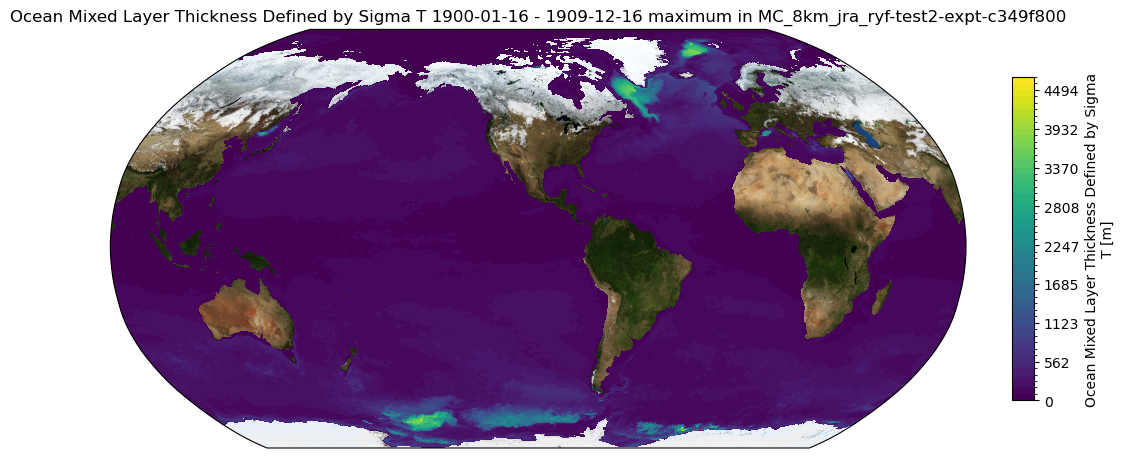

In [18]:
%%time
pnumber='0'
for timerange in timeranges:
    model_sliced = model_all.sel(time=timerange)
    model = model_sliced.max('time').load()
    plot(model,
        levels=51,
        vmin=0,
        vmax=None,
        # extend="max",
        cmap='viridis',
        pnum=pnumber,
        title=f"{model.attrs['long_name']} {model_sliced.time.values[0].strftime('%Y-%m-%d')} - {model_sliced.time.values[-1].strftime('%Y-%m-%d')} maximum in {exptname}"
        )
    pnumber=str(int(pnumber)+1)

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-5/mkmd/MLD_max_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-5/mkmd/MLD_max.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-5/mkmd/MLD_max.md successfully.
CPU times: user 5min 23s, sys: 1min 41s, total: 7min 4s
Wall time: 5min 30s


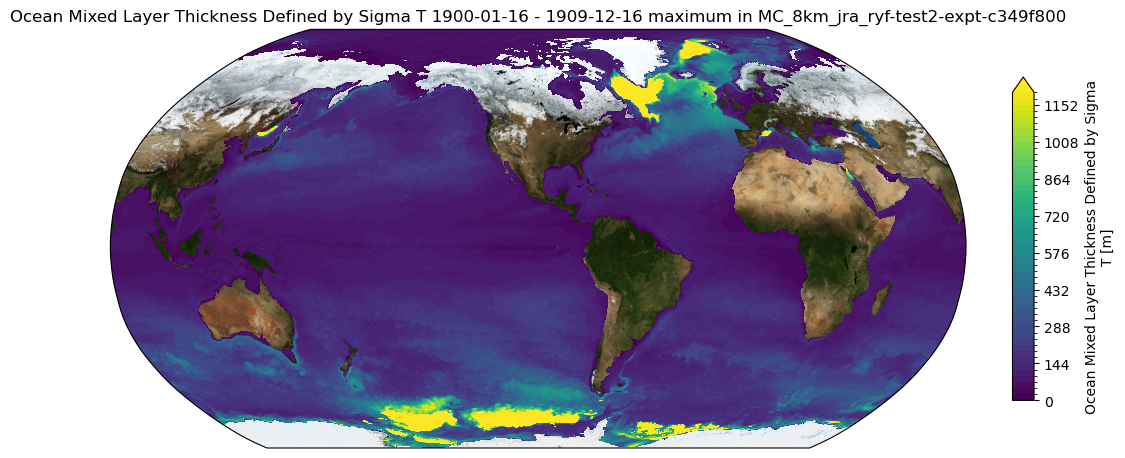

In [19]:
%%time
pnumber='10'
for timerange in timeranges:
    model_sliced = model_all.sel(time=timerange)
    model = model_sliced.max('time').load()
    plot(model,
        levels=51,
        vmin=0,
        vmax=1200,
        extend="max",
        cmap='viridis',
        title=f"{model.attrs['long_name']} {model_sliced.time.values[0].strftime('%Y-%m-%d')} - {model_sliced.time.values[-1].strftime('%Y-%m-%d')} maximum in {exptname}",
        pnum=pnumber
        )
    pnumber=str(int(pnumber)+1)

### Load and plot obs data from DeBoyer Montegut (2023)
https://doi.org/10.17882/91774

In [20]:
MLDobs = xr.open_dataset('/g/data/av17/access-nri/OM3/MLD-DeBoyerMontegut2023/mld_dr003_ref10m_v2023.nc')['mld_dr003']
MLDobs.attrs['units'] = MLDobs.attrs['unit']  # fix so plot works

# TODO: append copy of westernmost data to eastern end to avoid gap in plot

In [21]:
MLDobs_max = MLDobs.max('time').load()

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-5/mkmd/MLD_max_03.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-5/mkmd/MLD_max.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-5/mkmd/MLD_max.md successfully.


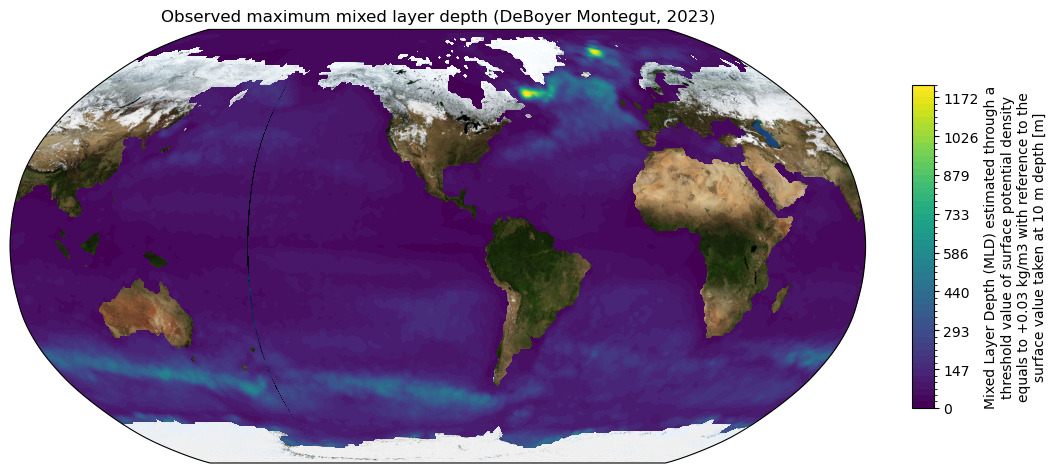

In [22]:
plot(MLDobs_max,
    levels=51,
    vmin=0,
    vmax=None,
    # extend="max",
    cmap='viridis',
    title=f"Observed maximum mixed layer depth (DeBoyer Montegut, 2023)",
    pnum='50')

In [23]:
client.close()